# 00 · Data Journey — from source to trustworthy analytics

**Goal:** Understand Extract → Validate → Model → Serve with no cloud account.

**Setup:** Python 3.11+; all example data is synthetic and defined in code.

**CS bridge:** Types, invariants and data provenance.

**Independence check:** Explain what can go wrong without a unique source event identifier.

## Watch and learn — Workflow Orchestration by DataTalks.Club

[**Watch the original video on YouTube**](https://www.youtube.com/watch?v=-JLnp-iLins). Suggested: choose a 5–15 minute segment on a concept you need to understand.

[![Video thumbnail](https://img.youtube.com/vi/-JLnp-iLins/hqdefault.jpg)](https://www.youtube.com/watch?v=-JLnp-iLins)

The next cell may display an embedded video in Jupyter/VS Code when internet access is available. GitHub's preview may not show it. You can complete every code exercise without watching the video.

In [1]:
# Optional video player (does not download or store the video)
try:
    from IPython.display import display, YouTubeVideo
    display(YouTubeVideo("-JLnp-iLins", width=720, height=405))
except ImportError:
    print("Open the YouTube link in the Markdown above.")

## 1. Opening question

An API returned seven records. Will the dashboard necessarily contain seven trustworthy events? State your prediction **before** running the next cell.

In [2]:
from collections import Counter
raw_events = [
    {"id": "a1", "magnitude": 2.6, "region": "North"},
    {"id": "a2", "magnitude": 4.1, "region": "East"},
    {"id": "a3", "magnitude": None, "region": "West"},
    {"id": "a4", "magnitude": -0.2, "region": "North"},  # magnitude can be negative in some scales
    {"id": "a2", "magnitude": 4.1, "region": "East"},  # replay
    {"id": None, "magnitude": 3.3, "region": "South"},
    {"id": "a5", "magnitude": 3.1, "region": "South"},
]
print("source rows:",len(raw_events))

source rows: 7


## 2. Define the contract: what makes a record valid?

For this demonstration, require a nonempty `id` and a numeric `magnitude`. **Teaching assumption:** negative magnitudes can be valid. A data-quality rule should reflect source semantics rather than blindly requiring values greater than zero.

In [3]:
def valid(record):
    return bool(record.get("id")) and isinstance(record.get("magnitude"),(int,float))
valid_rows = [r for r in raw_events if valid(r)]
rejected_rows = [r for r in raw_events if not valid(r)]
by_id = {r["id"]: r for r in valid_rows}
print({"source":len(raw_events),"valid_rows_in_source":len(valid_rows),"rejected":len(rejected_rows),"unique_curated":len(by_id)})
assert len(raw_events) == 7
assert len(rejected_rows) == 2
assert len(by_id) == 4

{'source': 7, 'valid_rows_in_source': 5, 'rejected': 2, 'unique_curated': 4}


## 3. Visualize and interpret

The chart shows record counts at different stages. Do not imply that rejected records were missing from the source: they arrived and were rejected under an explicit policy.

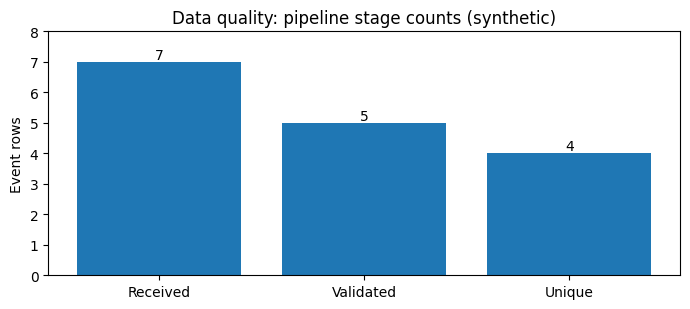

In [4]:
import matplotlib.pyplot as plt
stages = ["Received", "Validated", "Unique"]
counts = [len(raw_events),len(valid_rows),len(by_id)]
fig, ax=plt.subplots(figsize=(7,3.2))
ax.bar(stages,counts)
ax.set(title="Data quality: pipeline stage counts (synthetic)",ylabel="Event rows",ylim=(0,8))
for i,c in enumerate(counts):ax.text(i,c+0.1,str(c),ha="center")
plt.tight_layout();plt.show()

## 4. Independent checks

- Is `len(valid_rows)` greater than `len(by_id)`? Explain why.
- **No-AI exercise:** Add a record with `id='a5'` and magnitude 4.0. Predict how the chart changes. Is last-arrival-wins an appropriate update policy for a real source?
- **Extension:** Preserve `source_id`, `ingested_at` and `content_hash`. Explain why ingestion time differs from event time.

## Next steps

[Stage 00](../curriculum/modules/00.md) → [Notebook 01](01_sql_detective.ipynb). Run the repository tests and record answers in your reflection rather than putting them in raw data.